In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('names.txt').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
chars = sorted(list(set(''.join(words))))
stoi = {c : i+1 for i, c in enumerate(chars)} # create a mapping from character to index, starting from 1
stoi['.'] = 0
itos = {i : c for c, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [5]:
# Train split, Val split, Test Split
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?
def build_dataset(words):
    X, Y = [], []
    for w in words:
        
        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])        # 80%
Xdev, Ydev = build_dataset(words[n1:n2])    # 10%
Xte, Yte = build_dataset(words[n2:])        # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [8]:
n_embed = 10 # the dimentionality of the character embedding vectors
n_hidden = 200 # the number of neuron in hidden layer

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embed),              generator=g)

W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g)
b1 = torch.randn(n_hidden,                          generator=g)

W2 = torch.randn((n_hidden, vocab_size),            generator=g)
b2 = torch.randn(vocab_size,                        generator=g)

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

11897


In [ ]:
max_steps = 200
batch_size = 32
lossi = []

for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # (start, end, size)  <== batch size = 32
    Xb, Yb = Xtr[ix], Ytr[ix] # batch

    # forward pass
    emb = C[Xb]  # embed characters into vectors
    emb_cat = emb.view(emb.shape[0], -1) # concatenate context vectors in single instance together
    z1 = emb_cat @ W1 + b1 # hidden pre activation
    h = torch.tanh(z1) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update parameters
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')

    lossi.append(loss.log10().item())

print(f"Epoch {i+1} | loss: {loss.item():.4f}")

      0/ 200000: 27.8817
  10000/ 200000: 2.8137
  20000/ 200000: 2.5107
  30000/ 200000: 2.8047
  40000/ 200000: 2.0610
  50000/ 200000: 2.6743
  60000/ 200000: 2.3679
  70000/ 200000: 2.0702
  80000/ 200000: 2.2550
  90000/ 200000: 2.2825


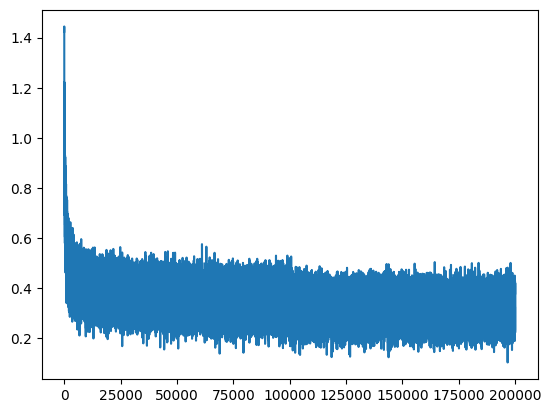

In [ ]:
plt.plot(lossi)

In [6]:
splits = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
}

In [9]:
@torch.no_grad() # disable gradient tracking
def split_loss(split):
    x, y = splits[split]
    emb = C[x]  # (N, block_size, n_embed). block_size=context length
    emb_cat = emb.view(emb.shape[0], -1) # (N, block_size * n_embed)
    z1 = emb_cat @ W1 + b1 # (N, n_hidden)
    h = torch.tanh(z1) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())


split_loss('train')
split_loss('val')
    

train 26.004695892333984
val 26.010541915893555


In [ ]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)
with torch.no_grad():
    for _ in range(20):
        out = []
        context = [0] * block_size # initialize with all ...
        while True:
            # forward pass
            emb = C[torch.tensor([context])] # (1, block_size, n_embed)
            h = torch.tanh(emb.view(1, -1) @ W1 + b1)
            logits = h @ W2 + b2
            probs = F.softmax(logits, dim=1)
            # sample from the distribution
            ix = torch.multinomial(probs, num_samples=1, generator=g).item()
            context = context[1:] + [ix]
            out.append(ix)
            if ix == 0:
                break
                
        print(''.join(itos[i] for i in out))

mora.
kmyah.
see.
med.
ryah.
rethan.
endrae.
cadejedieliianny.
jen.
eden.
estanar.
katelmi.
karin.
shubergiagriel.
kindreeller.
nopatrius.
kace.
ryyah.
fael.
yume.


In [ ]:
-torch.tensor(1/27.0).log()

tensor(3.2958)

There are many problems in a way we initialized out weights:

At the first step of training, the loss was very high(0/ 200000: 26.5404). We wasn't expecting that high loss. 
At the start, even if we assign uniform probability to each character, loss would have been 3.29


In [ ]:
# 4-dimentional view of the issue
logits_list = [torch.tensor([0.1, 0.1, 0.1, 0.1]), torch.tensor([0.01, 0.01, 5.0, 0.01]), torch.tensor([0.01, 5.0, 0.01, 0.01]), torch.randn(4) * 10]

for logits in logits_list:
    probs = torch.softmax(logits, dim=0)
    loss = -probs[2].log() # 2 is the correct class -> loss is less if it has high val
    print(logits)
    print(probs)
    print(loss)
    print('--------------------------------------------------')

tensor([0.1000, 0.1000, 0.1000, 0.1000])
tensor([0.2500, 0.2500, 0.2500, 0.2500])
tensor(1.3863)
--------------------------------------------------
tensor([0.0100, 0.0100, 5.0000, 0.0100])
tensor([0.0067, 0.0067, 0.9800, 0.0067])
tensor(0.0202)
--------------------------------------------------
tensor([0.0100, 5.0000, 0.0100, 0.0100])
tensor([0.0067, 0.9800, 0.0067, 0.0067])
tensor(5.0102)
--------------------------------------------------
tensor([-14.3433,  15.0456,   2.0128,   5.4239])
tensor([1.7241e-13, 9.9993e-01, 2.1873e-06, 6.6274e-05])
tensor(13.0328)
--------------------------------------------------


In [ ]:
'''
tensor([-14.3433,  15.0456,   2.0128,   5.4239])
tensor([1.7241e-13, 9.9993e-01, 2.1873e-06, 6.6274e-05])
tensor(13.0328)

if logits get extreme values, we are getting very high loss, not good.

we want logits to be roughly zero and approximatly equal at the time of initialization

'''

In [ ]:
n_embed = 10 # the dimentionality of the character embedding vectors
n_hidden = 200 # the number of neuron in hidden layer

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embed),              generator=g)

W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g)
b1 = torch.randn(n_hidden,                          generator=g)

W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01 # scaling down w2 because logit calculation involves w2. (logits = h @ W2 + b2)
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

11897


In [ ]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # (start, end, size)  <== batch size = 32
    Xb, Yb = Xtr[ix], Ytr[ix] # batch

    # forward pass
    emb = C[Xb]  # embed characters into vectors
    emb_cat = emb.view(emb.shape[0], -1) # concatenate context vectors in single instance together
    z1 = emb_cat @ W1 + b1 # hidden pre activation
    h = torch.tanh(z1) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update parameters
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')

    lossi.append(loss.log10().item())

print(f"Epoch {i+1} | loss: {loss.item():.4f}")

      0/ 200000: 3.2459
  10000/ 200000: 2.3544
  20000/ 200000: 2.0843
  30000/ 200000: 2.3805
  40000/ 200000: 2.5993
  50000/ 200000: 2.1307
  60000/ 200000: 2.3376
  70000/ 200000: 1.8359
  80000/ 200000: 2.1580
  90000/ 200000: 2.2627
 100000/ 200000: 2.2407
 110000/ 200000: 1.8451
 120000/ 200000: 2.3030
 130000/ 200000: 2.2558
 140000/ 200000: 1.9463
 150000/ 200000: 2.3495
 160000/ 200000: 2.1755
 170000/ 200000: 2.2178
 180000/ 200000: 2.2059
 190000/ 200000: 1.8093
Epoch 200000 | loss: 2.0880


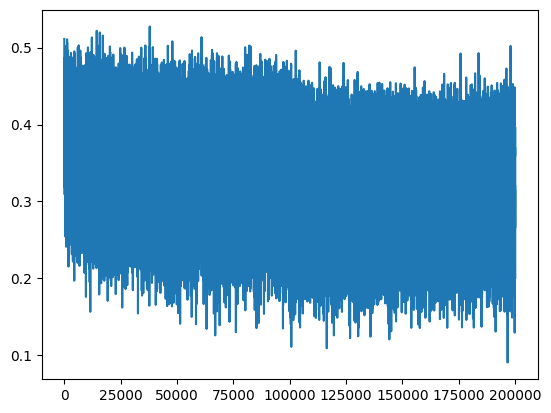

In [ ]:
plt.plot(lossi) 

So we can say that we are not wasting initial steps to bring down the weights. 

The second problem is about hidden state(h).
Many values of h are either -1 or 1

In [ ]:
h

tensor([[-1.0000, -0.9963, -0.9974,  ...,  1.0000,  0.9980,  0.9999],
        [-0.9999, -1.0000, -1.0000,  ...,  0.7289, -0.9999, -1.0000],
        [-0.9994, -1.0000, -0.9999,  ..., -0.6031,  0.9971, -0.9996],
        ...,
        [-1.0000, -1.0000, -1.0000,  ..., -1.0000,  0.4162,  0.3119],
        [-0.3352, -1.0000,  1.0000,  ...,  0.0194,  0.9321,  1.0000],
        [ 0.6960, -1.0000, -0.3779,  ...,  0.4754, -1.0000, -0.8408]],
       grad_fn=<TanhBackward0>)

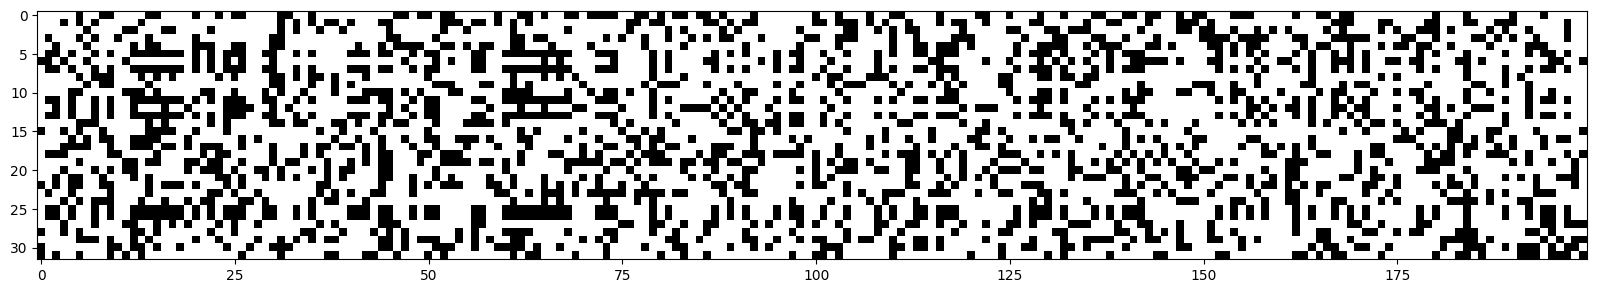

In [ ]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest');


Here white dot means tanh of that hidden item is ~1(this value being in the flat region of tanh curve) and black means it is less than 0.99

In [ ]:
print(h.shape)
print(h.view(-1).shape)

torch.Size([32, 200])
torch.Size([6400])


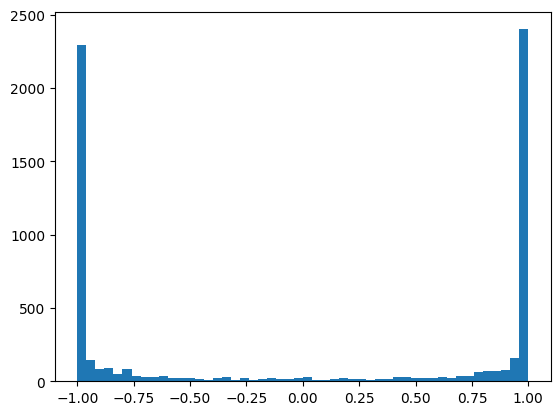

In [ ]:
plt.hist(h.view(-1).tolist(), 50);

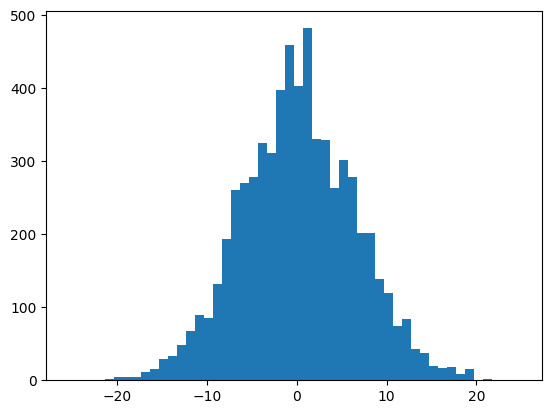

In [ ]:
plt.hist(z1.view(-1).tolist(), 50);

There are lots of values far from 0, so they are curbed down to -1 or 1 by tanh

Problem: We apply tanh element wise (torch.tanh(z1))

The gradient of tanh is '(1 - t**2) * out.grad' <-- by micrograd

This will be 0 for if tanh output is near 1 or -1

So, gradient(or out.grad) will not flow backward(it vanishes)

In [ ]:
n_embed = 10 # the dimentionality of the character embedding vectors
n_hidden = 200 # the number of neuron in hidden layer

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embed),              generator=g)

W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * 0.2
b1 = torch.randn(n_hidden,                          generator=g) * 0.01

W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01 # scaling down w2 because logit calculation involves w2. (logits = h @ W2 + b2)
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

11897


In [ ]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # (start, end, size)  <== batch size = 32
    Xb, Yb = Xtr[ix], Ytr[ix] # batch

    # forward pass
    emb = C[Xb]  # embed characters into vectors
    emb_cat = emb.view(emb.shape[0], -1) # concatenate context vectors in single instance together
    z1 = emb_cat @ W1 + b1 # hidden pre activation
    h = torch.tanh(z1) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update parameters
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')

    lossi.append(loss.log10().item())
    break

print(f"Epoch {i+1} | loss: {loss.item():.4f}")

      0/ 200000: 3.3091
Epoch 1 | loss: 3.3091


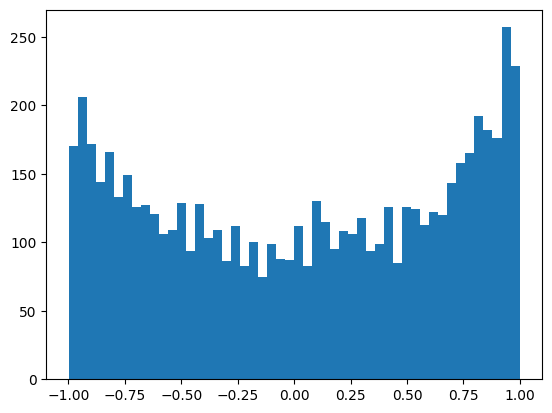

In [ ]:
plt.hist(h.view(-1).tolist(), 50);

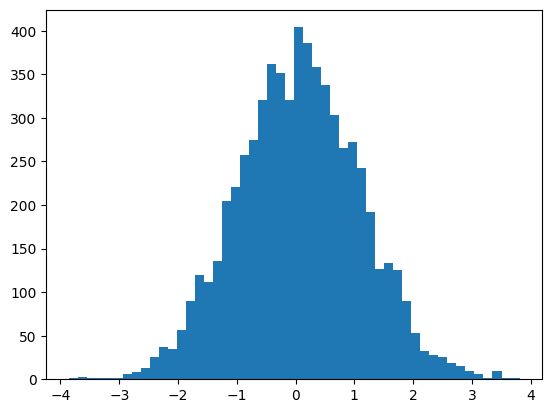

In [ ]:
plt.hist(z1.view(-1).tolist(), 50);

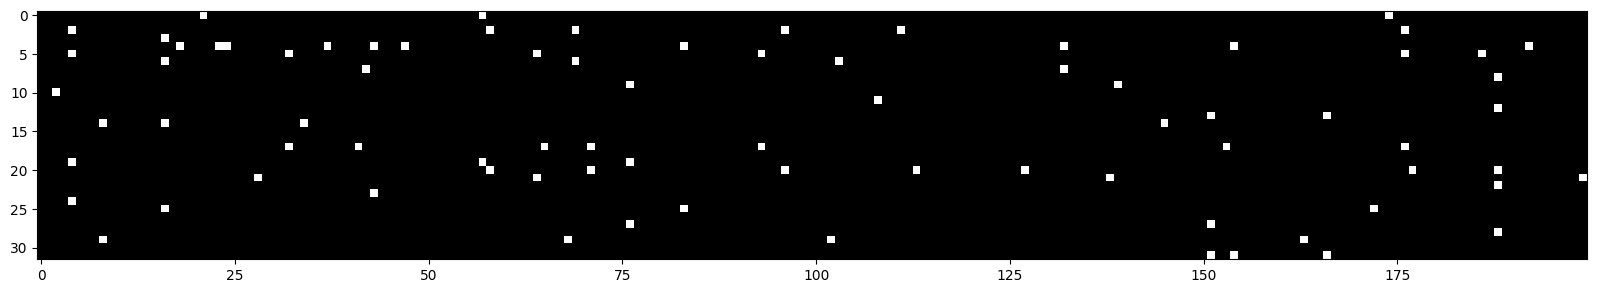

In [ ]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest');

This means very less neurons saturated on -1 or 1 of tanh

      0/ 200000: 3.2233
  10000/ 200000: 2.1705
  20000/ 200000: 2.4650
  30000/ 200000: 2.1193
  40000/ 200000: 1.9937
  50000/ 200000: 2.1310
  60000/ 200000: 2.2194
  70000/ 200000: 2.2307
  80000/ 200000: 2.1740
  90000/ 200000: 2.2503
 100000/ 200000: 1.7831
 110000/ 200000: 1.9758
 120000/ 200000: 2.1643
 130000/ 200000: 2.1341
 140000/ 200000: 2.1869
 150000/ 200000: 2.2806
 160000/ 200000: 1.8779
 170000/ 200000: 2.1529
 180000/ 200000: 2.2115
 190000/ 200000: 1.8841
Epoch 200000 | loss: 1.8879


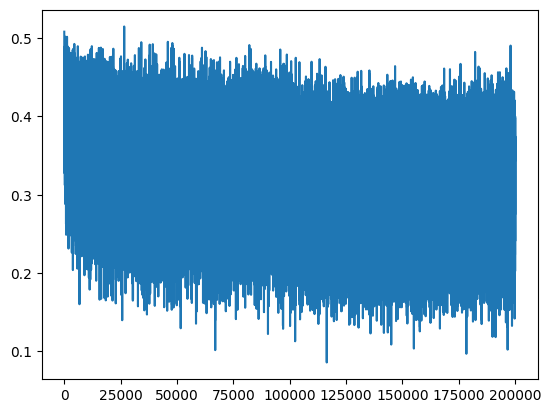

In [ ]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # (start, end, size)  <== batch size = 32
    Xb, Yb = Xtr[ix], Ytr[ix] # batch

    # forward pass
    emb = C[Xb]  # embed characters into vectors
    emb_cat = emb.view(emb.shape[0], -1) # concatenate context vectors in single instance together
    z1 = emb_cat @ W1 + b1 # hidden pre activation
    h = torch.tanh(z1) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update parameters
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')

    lossi.append(loss.log10().item())

print(f"Epoch {i+1} | loss: {loss.item():.4f}")
plt.plot(lossi);

In [ ]:
split_loss('train')
split_loss('val')

train 2.0340521335601807
val 2.102104902267456


Loss log:<br/><br/>

original<br/>
train: 2.12<br/>
val  : 2.16<br/>
<br/>
fix softmax confidently wrong<br/>
train: 2.07<br/>
val  : 2.13<br/>
<br/>
fix tanh layer too saturated at init<br/>
train: 2.03<br/>
val  : 2.10<br/>

tensor(-0.0057) tensor(1.0098)
tensor(0.0097) tensor(3.1719)


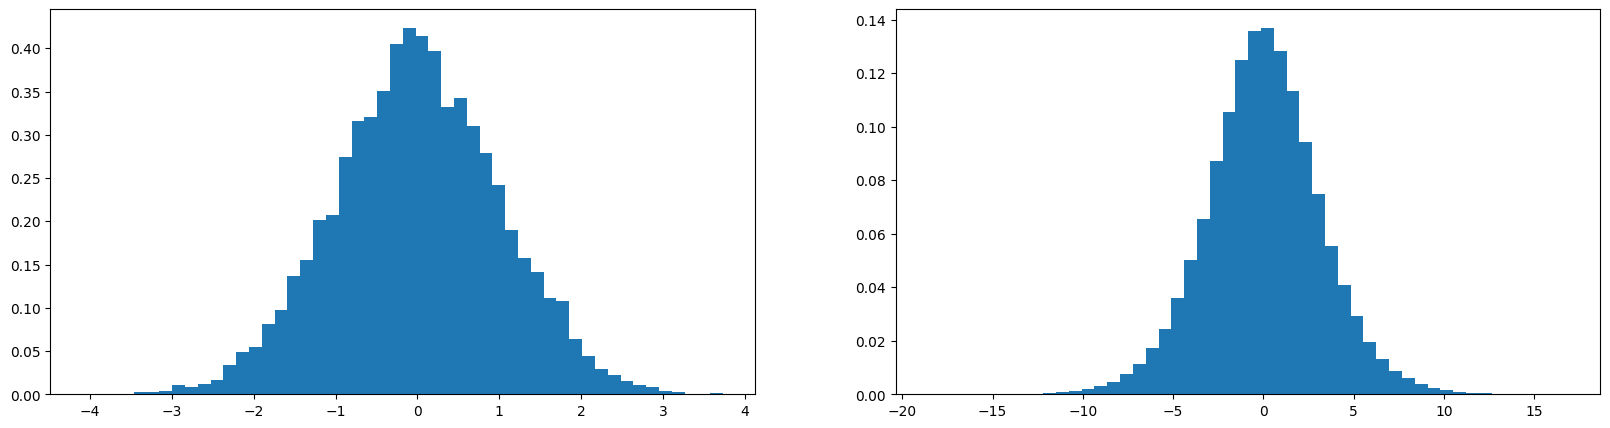

In [ ]:
x = torch.randn(1000, 10) # 1000 example, each of dim 10
w = torch.randn(10, 200) # layer with 200 neurons with input of size 10
y = x @ w 
print(x.mean(), x.std())
print(y.mean(), y.std())
plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density=True);
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True);

Here standard deviation of y is very different(higher) than the input x

After multipying x with w, it is distorting the std/distribution of x

we want the std of y should remain approx equal to the input

what should we do, => divide w with sqrt(size of input[also called fan-in])

kaimin initialization formula = gain / sqrt(fan-in)
.. gain for tanh = 5/3


tensor(-0.0125) tensor(0.9989)
tensor(-0.0037) tensor(0.9763)


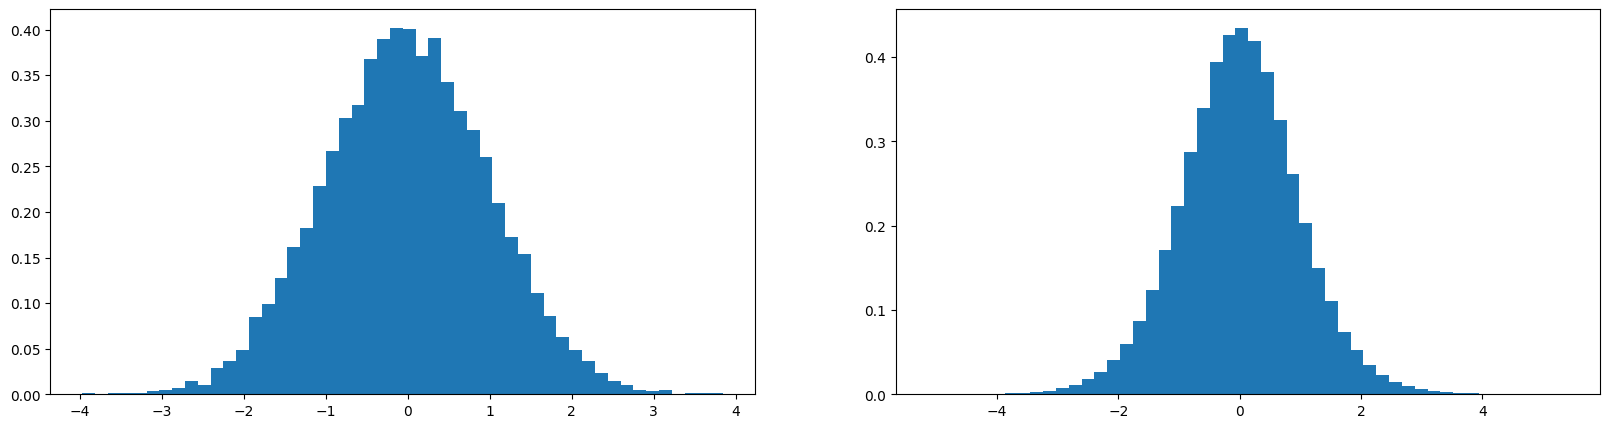

In [ ]:
x = torch.randn(1000, 10) # 1000 example, each of dim 10
w = torch.randn(10, 200) / 10**0.5 # layer with 200 neurons with input of size 10
y = x @ w 
print(x.mean(), x.std())
print(y.mean(), y.std())
plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density=True);
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density=True);

In [ ]:
n_embed = 10 # the dimentionality of the character embedding vectors
n_hidden = 200 # the number of neuron in hidden layer

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_embed),              generator=g)

W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)
b1 = torch.randn(n_hidden,                          generator=g) * 0.01

W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01 # scaling down w2 because logit calculation involves w2. (logits = h @ W2 + b2)
b2 = torch.randn(vocab_size,                        generator=g) * 0

parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

11897


      0/    200: 27.8817
Epoch 200 | loss: 6.3533


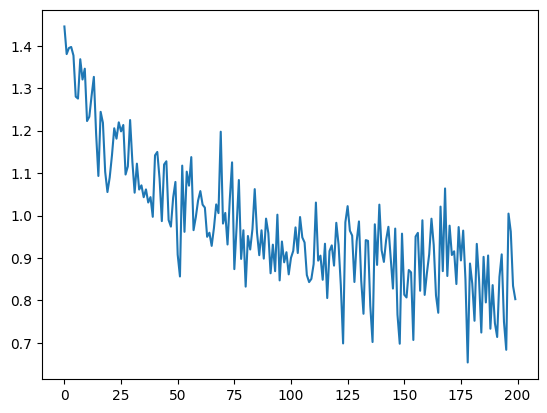

In [11]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g) # (start, end, size)  <== batch size = 32
    Xb, Yb = Xtr[ix], Ytr[ix] # batch

    # forward pass
    emb = C[Xb]  # embed characters into vectors
    emb_cat = emb.view(emb.shape[0], -1) # concatenate context vectors in single instance together
    z1 = emb_cat @ W1 + b1 # hidden pre activation
    h = torch.tanh(z1) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update parameters
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')

    lossi.append(loss.log10().item())

print(f"Epoch {i+1} | loss: {loss.item():.4f}")
plt.plot(lossi);

In [ ]:
split_loss('train')
split_loss('val')

train 2.0376152992248535
val 2.1030640602111816


### Batch Normalization

we want out 'zi' (pre-activations) to be roughly gaussian to control their scale. If its too large or too small it can saturate activation functions output i.e. hidden state 'h'.

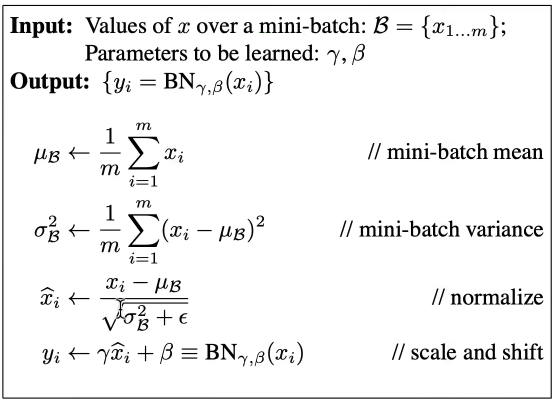

In [12]:
z1.shape

torch.Size([32, 200])

In [13]:
z1.mean(dim=0, keepdim=True).shape

torch.Size([1, 200])

In [15]:
z1.std(dim=0, keepdim=True).shape

torch.Size([1, 200])

In [52]:
device = 'cpu'
# Train split, Val split, Test Split
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?
def build_dataset(words):
    X, Y = [], []
    for w in words:
        
        #print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            #print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X, device=device)
    Y = torch.tensor(Y, device=device)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])        # 80%
Xdev, Ydev = build_dataset(words[n1:n2])    # 10%
Xte, Yte = build_dataset(words[n2:])        # 10%

torch.Size([182424, 3]) torch.Size([182424])
torch.Size([22836, 3]) torch.Size([22836])
torch.Size([22886, 3]) torch.Size([22886])


In [53]:
n_embed = 10 # the dimentionality of the character embedding vectors
n_hidden = 200 # the number of neuron in hidden layer


g = torch.Generator(device=device).manual_seed(2147483647)
C = torch.randn((vocab_size, n_embed),              generator=g, device=device)

W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g, device=device) * (5/3) / ((n_embed * block_size) ** 0.5)
# b1 = torch.randn(n_hidden,                          generator=g) * 0.01

W2 = torch.randn((n_hidden, vocab_size),            generator=g, device=device) * 0.01 # scaling down w2 because logit calculation involves w2. (logits = h @ W2 + b2)
b2 = torch.randn(vocab_size,                        generator=g, device=device) * 0

bn_gain = torch.ones((1, n_hidden), device=device) # batch normalization gain
bn_bias = torch.zeros((1, n_hidden), device=device) # batch normalization bias

## At the time of initialization, W1 is initialized roughly unit gaussian so the mean of batch would be roughly zero and std would be roughly one
## so we initialized it the same
bn_mean_running = torch.zeros((1, n_hidden), device=device)
bn_std_running = torch.ones((1, n_hidden), device=device)

parameters = [C, W1, bn_gain, bn_bias, W2, b2]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True


12097


Firing rate of each neuron will be exactly unit gaussian for current batch

We dont want it to remain exactly unit gaussiun(zero mean) every time, we want it exactly unit gaussian at the time of initialization. While the training, the neural network must be able to spread or shift the distribution according to need

we can acheve this by multiplying normalized z with some parameters(gain) and adding some parameter(bias). These gain and bias will also be learned. These are also parameters of network.

--------------------------------------------------------------------------------------------
Whenever we use a batch normalization layer we dont use bias(b1 in this case) in that layer. Because we are subtracting mean from the batch, the effect of bias negets.
It will never get any gradient and it will stay constant only.

We can remove the b1. 

Batch normalization bias will handle the work of biasing the distribution.


_________________________________________________________________________________________________
Batch normalization is not used now a days because it introduces many bugs, doesn't allow paralalalization
other alternatives: group normalization, layer normalization

      0/ 200000: 3.3064
  10000/ 200000: 2.2686
  20000/ 200000: 2.1615
  30000/ 200000: 1.9873
  40000/ 200000: 1.8749
  50000/ 200000: 2.3076
  60000/ 200000: 2.0587
  70000/ 200000: 2.3989
  80000/ 200000: 2.3724
  90000/ 200000: 2.2505
 100000/ 200000: 2.4910
 110000/ 200000: 2.3039
 120000/ 200000: 2.0946
 130000/ 200000: 2.1231
 140000/ 200000: 2.0614
 150000/ 200000: 2.0781
 160000/ 200000: 1.8938
 170000/ 200000: 2.2478
 180000/ 200000: 2.1415
 190000/ 200000: 1.9682
Epoch 200000 | loss: 1.9918


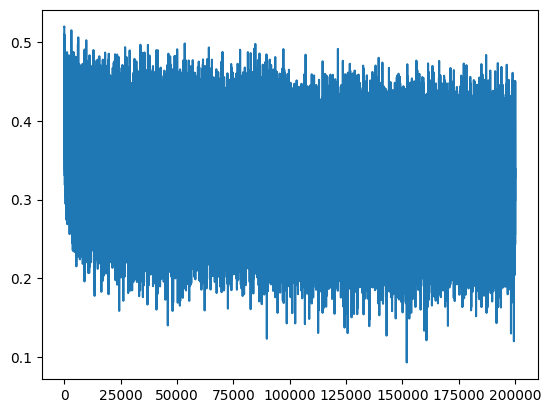

In [54]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g, device=device) # (start, end, size)  <== batch size = 32
    Xb, Yb = Xtr[ix], Ytr[ix] # batch

    # forward pass
    emb = C[Xb]  # embed characters into vectors
    emb_cat = emb.view(emb.shape[0], -1) # concatenate context vectors in single instance together
    z1 = emb_cat @ W1 # + b1 # hidden pre activation

    ## --------------------------Batch Normalization Layer-----------------------------
    bn_mean_i = z1.mean(dim=0, keepdim=True)
    bn_std_i = z1.std(dim=0, keepdim=True)
    z1 = bn_gain * ((z1 - bn_mean_i) / bn_std_i) + bn_bias
    # z1 = bn_gain * z1 + bn_bias

    with torch.no_grad():
        bn_mean_running = bn_mean_running * 0.999 + 0.001 * bn_mean_i
        bn_std_running = bn_std_running * 0.999 + 0.001 * bn_std_i

    ## -----------------------------------------------------=--------------------------
    h = torch.tanh(z1) # hidden layer
    logits = h @ W2 + b2 # output layer
    loss = F.cross_entropy(logits, Yb) # loss function

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update parameters
    lr = 0.1 if i < 100000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')

    lossi.append(loss.log10().item())

print(f"Epoch {i+1} | loss: {loss.item():.4f}")
plt.plot(lossi);

Batch normalization does one more thing. It couples each example of the batch with all other examples of the same batch(less parallalize possible).

It adds little jitter/noise to each training sample, and this noise is depend on other examples of batch. 

Batch is sampled randomly. So it makes harder for neural network to overfit any example(kind of regularization).

One more problem is there, when we deploy a neural network in production environment, it gets single example as an input and output the predicton for that single example.

So what will it do for batch mean and batch std?

Solution given by paper: Save the bn_mean and bn_std over complete training set and use that mean and std at the time of test.

In [28]:
# calculate the batch norm at the end of training 
with torch.no_grad():
    emb = C[Xtr]
    emb_cat = emb.view(emb.shape[0], -1)
    z = emb_cat @ W1 + b1
    bn_mean = z.mean(dim=0, keepdim = True)
    bn_std = z.std(dim=0, keepdim = True)

##### most of the time, it is calculated at the time of training only using one technique. 
##### We can keep a running mean and bias and update it with current batch's mean and bias.

In [32]:
print(bn_mean[0][:16])

print(bn_mean_running[0][:16])

tensor([-2.3355,  0.6775, -0.9133,  1.0163,  1.0865,  1.0938,  1.7437, -2.1208,
         0.5730,  1.4455, -1.6344, -2.7372, -0.4752, -0.1412, -0.0745, -1.1722])
tensor([-2.3539,  0.6872, -0.9000,  1.0159,  1.0894,  1.0862,  1.7389, -2.1356,
         0.5608,  1.4246, -1.6445, -2.7426, -0.4861, -0.1510, -0.0687, -1.1550])


In [33]:
print(bn_std[0][:18])

print(bn_std_running[0][:18])

tensor([2.3928, 2.1364, 2.2663, 1.9944, 2.1860, 2.3736, 2.2576, 2.3451, 2.3578,
        2.1044, 2.4973, 2.2571, 2.1519, 2.2017, 2.0989, 2.7105, 2.4423, 1.8901])
tensor([2.3689, 2.0998, 2.2499, 1.9599, 2.1515, 2.3429, 2.2431, 2.3104, 2.3309,
        2.0823, 2.4680, 2.2253, 2.1192, 2.1805, 2.0655, 2.6865, 2.4191, 1.8718])


In [35]:
splits = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
}

@torch.no_grad() # disable gradient tracking
def split_loss(split):
    x, y = splits[split]
    emb = C[x]  # (N, block_size, n_embed). block_size=context length
    emb_cat = emb.view(emb.shape[0], -1) # (N, block_size * n_embed)
    z1 = emb_cat @ W1 #+ b1 # (N, n_hidden)
    z1 = bn_gain * ((z1 - bn_mean) / bn_std) + bn_bias
    h = torch.tanh(z1) # (N, n_hidden)
    logits = h @ W2 + b2 # (N, vocab_size)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 3.3081037998199463
val 3.3077456951141357


Lets create proper network, much like pytorch

In [69]:
g = torch.Generator().manual_seed(2147483647)
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x: torch.Tensor):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1D:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.dim = dim
        self.training = True

        # parameters (trained with backpropagation)
        self.gamma = torch.ones((1, dim)) # gain
        self.beta = torch.zeros((1, dim)) # bias

        # buffers (updated using momentum)
        self.running_mean = torch.zeros((1, dim))
        self.running_var = torch.ones((1, dim))

    def __call__(self, x: torch.Tensor):
        if self.training: 
            xmean = x.mean(dim=0, keepdim=True) # batch mean
            xvar = x.var(dim=0, keepdim=True, unbiased=True) # batch variance
        else:
            xmean = self.running_mean
            xvar = self.running_var

        x_hat = (x - xmean) / torch.sqrt(xvar + self.eps)

        self.out = self.gamma * x_hat + self.beta

        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar

        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []


In [107]:
n_embed = 10 # embedding vector dim
e_hidden = 100 # number of neurons in hidden layer

C = torch.randn((vocab_size, n_embed), generator=g)

layers = [
    Linear(n_embed * block_size, n_hidden),
    Tanh(),

    Linear(n_hidden, n_hidden),
    Tanh(),

    Linear(n_hidden, n_hidden),
    Tanh(),

    Linear(n_hidden, n_hidden),
    Tanh(),

    Linear(n_hidden, n_hidden),
    Tanh(),

    Linear(n_hidden, vocab_size)
]

with torch.no_grad():
    #last layer: make less confident
    layers[-1].weight *= 0.1

    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print("Number of parameters :", sum(p.nelement() for p in parameters))

for p in parameters:
    p.requires_grad = True


Number of parameters : 172697


In [108]:
# training

max_steps = 200000
batch_size = 32
lossi = []
update_to_data = []

for i in range(max_steps):
    # minibactch
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator=g)
    Xb, yb = Xtr[ix], Ytr[ix]

    # Forward Pass
    emb = C[Xb]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)

    loss = F.cross_entropy(x, yb) # loss function

    # backard pass
    for layer in layers:
        layer.out.retain_grad()

    for p in parameters:
        p.grad = None
        
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    with torch.no_grad():
        update_to_data.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])

    if i > 1000:
        break
    

      0/ 200000: 3.3119


layer 1 (      Tanh): mean -0.01, std 0.78, saturated: 25.92%
layer 3 (      Tanh): mean +0.03, std 0.73, saturated: 14.58%
layer 5 (      Tanh): mean -0.01, std 0.73, saturated: 13.30%
layer 7 (      Tanh): mean +0.02, std 0.72, saturated: 11.80%
layer 9 (      Tanh): mean -0.02, std 0.68, saturated: 8.09%


Text(0.5, 1.0, 'activation distribution')

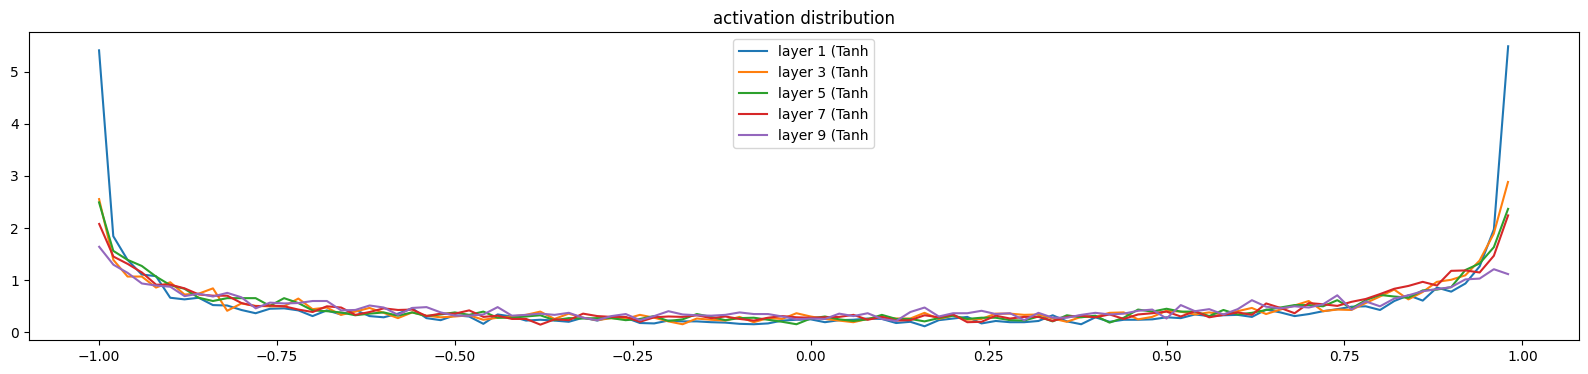

In [109]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

layer 1 (      Tanh): mean +0.000025, std 1.915959e-03
layer 3 (      Tanh): mean -0.000031, std 1.834889e-03
layer 5 (      Tanh): mean +0.000005, std 1.762513e-03
layer 7 (      Tanh): mean -0.000012, std 1.665831e-03
layer 9 (      Tanh): mean +0.000008, std 1.356822e-03


Text(0.5, 1.0, 'gradient distribution')

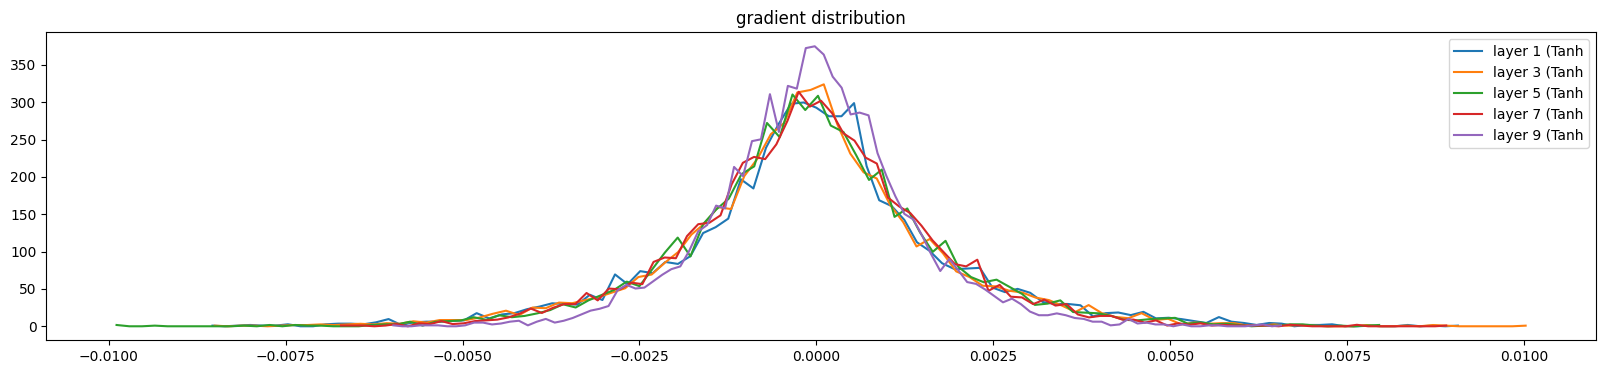

In [110]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')

weight   (27, 10) | mean +0.000257 | std 1.001184e-02 | grad:data ratio 9.614460e-03
weight  (30, 200) | mean +0.000061 | std 6.007089e-03 | grad:data ratio 1.941377e-02
weight (200, 200) | mean -0.000007 | std 4.709098e-03 | grad:data ratio 3.961780e-02
weight (200, 200) | mean +0.000031 | std 4.292962e-03 | grad:data ratio 3.614241e-02
weight (200, 200) | mean -0.000008 | std 3.905626e-03 | grad:data ratio 3.294930e-02
weight (200, 200) | mean -0.000018 | std 3.483535e-03 | grad:data ratio 2.976789e-02
weight  (200, 27) | mean -0.000000 | std 2.071602e-02 | grad:data ratio 4.380241e-01


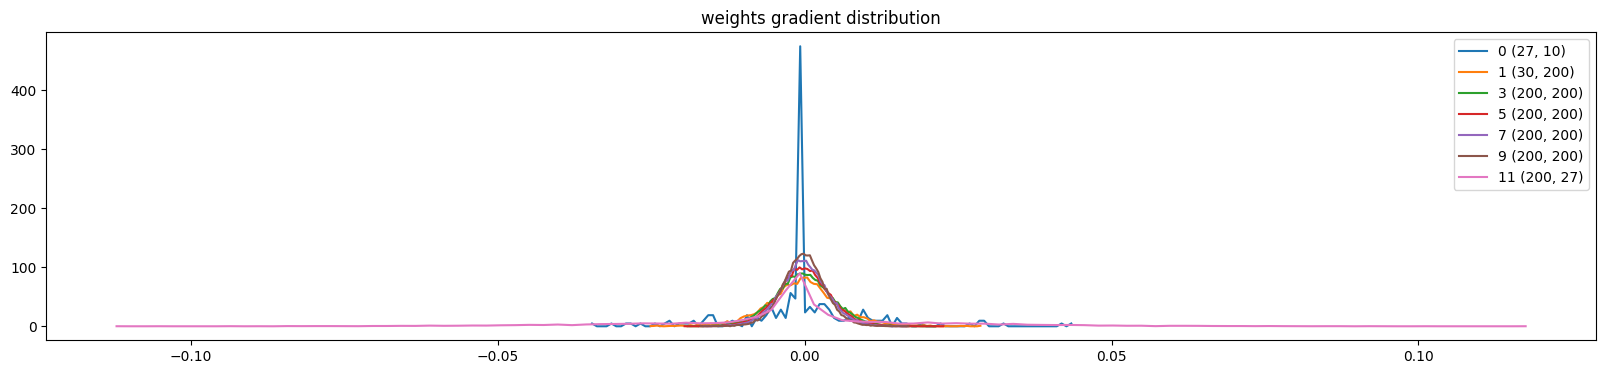

In [111]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2: ## checking only weights
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

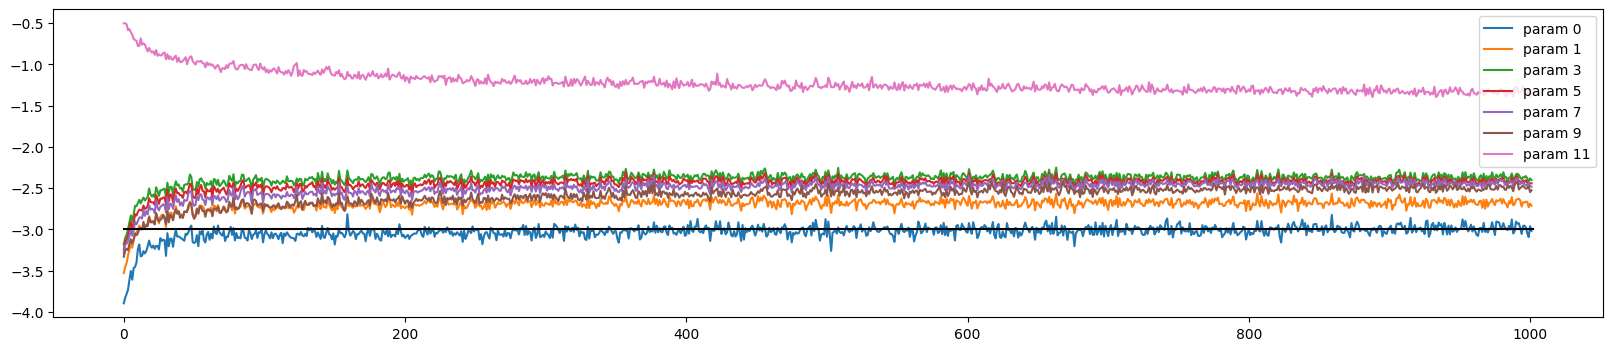

In [112]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([update_to_data[j][i] for j in range(len(update_to_data))])
    legends.append('param %d' % i)
plt.plot([0, len(update_to_data)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);

Now lets add BatchNor Layer

In [113]:
n_embed = 10 # embedding vector dim
e_hidden = 100 # number of neurons in hidden layer

C = torch.randn((vocab_size, n_embed), generator=g)

layers = [
    Linear(n_embed * block_size, n_hidden, bias=False),
    BatchNorm1D(n_hidden),
    Tanh(),

    Linear(n_hidden, n_hidden, bias=False),
    BatchNorm1D(n_hidden),
    Tanh(),

    Linear(n_hidden, n_hidden, bias=False),
    BatchNorm1D(n_hidden),
    Tanh(),

    Linear(n_hidden, n_hidden, bias=False),
    BatchNorm1D(n_hidden),
    Tanh(),

    Linear(n_hidden, n_hidden, bias=False),
    BatchNorm1D(n_hidden),
    Tanh(),

    Linear(n_hidden, vocab_size, bias=False),
    BatchNorm1D(vocab_size),
]

with torch.no_grad():
    #last layer: make less confident
    layers[-1].gamma *= 0.1
    # layers[-1].weight *= 0.1

    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print("Number of parameters :", sum(p.nelement() for p in parameters))

for p in parameters:
    p.requires_grad = True


Number of parameters : 173724


In [114]:
# training

max_steps = 200000
batch_size = 32
lossi = []
update_to_data = []

for i in range(max_steps):
    # minibactch
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator=g)
    Xb, yb = Xtr[ix], Ytr[ix]

    # Forward Pass
    emb = C[Xb]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)

    loss = F.cross_entropy(x, yb) # loss function

    # backard pass
    for layer in layers:
        layer.out.retain_grad()

    for p in parameters:
        p.grad = None
        
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    with torch.no_grad():
        update_to_data.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])

    if i > 1000:
        break
    

      0/ 200000: 3.3155


layer 2 (      Tanh): mean +0.00, std 0.63, saturated: 3.31%
layer 5 (      Tanh): mean -0.00, std 0.63, saturated: 3.08%
layer 8 (      Tanh): mean +0.00, std 0.64, saturated: 2.62%
layer 11 (      Tanh): mean +0.00, std 0.65, saturated: 2.06%
layer 14 (      Tanh): mean +0.00, std 0.65, saturated: 1.77%


Text(0.5, 1.0, 'activation distribution')

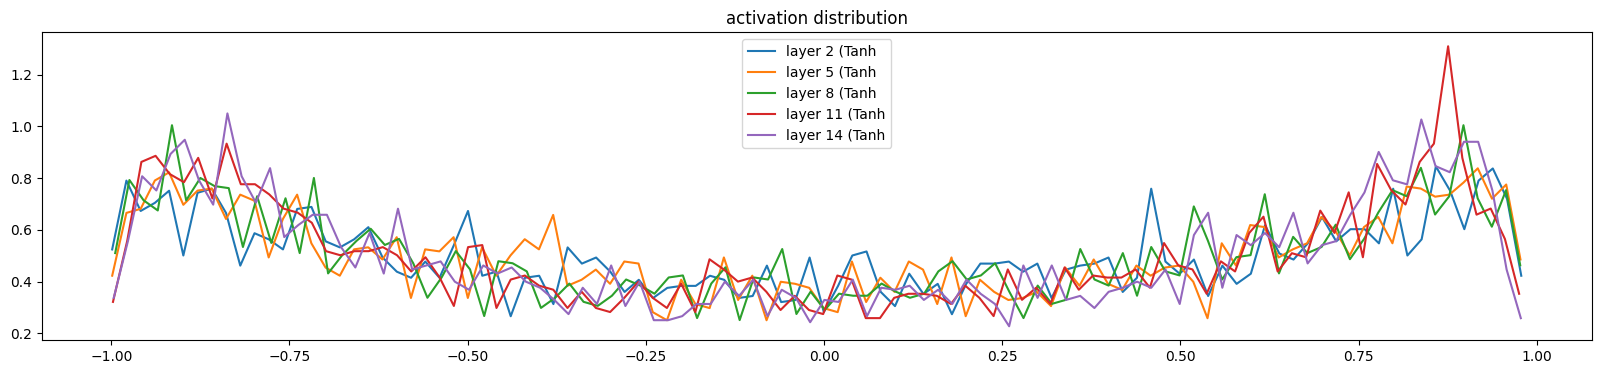

In [115]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

layer 2 (      Tanh): mean +0.000000, std 1.851446e-03
layer 5 (      Tanh): mean -0.000000, std 1.583015e-03
layer 8 (      Tanh): mean -0.000000, std 1.479993e-03
layer 11 (      Tanh): mean +0.000000, std 1.406351e-03
layer 14 (      Tanh): mean -0.000000, std 1.380499e-03


Text(0.5, 1.0, 'gradient distribution')

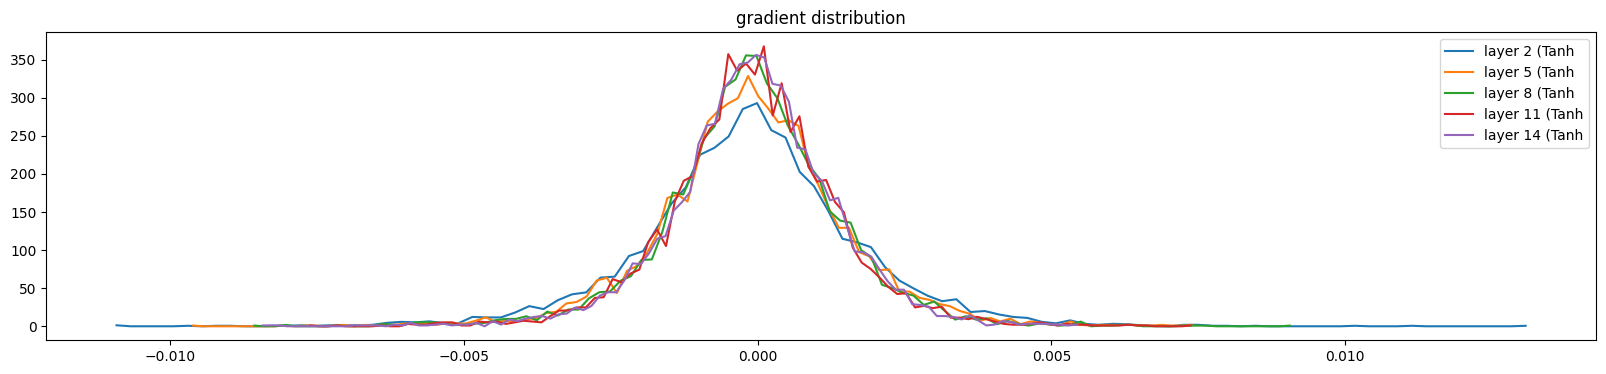

In [116]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')

weight   (27, 10) | mean +0.000000 | std 8.540871e-03 | grad:data ratio 8.517544e-03
weight  (30, 200) | mean +0.000018 | std 4.414087e-03 | grad:data ratio 1.441521e-02
weight   (1, 200) | mean +0.000008 | std 3.140103e-03 | grad:data ratio 2.304761e-01
weight   (1, 200) | mean +0.000467 | std 3.503646e-03 | grad:data ratio 2.004708e-01
weight (200, 200) | mean +0.000013 | std 3.409530e-03 | grad:data ratio 2.876693e-02
weight   (1, 200) | mean +0.000141 | std 2.689944e-03 | grad:data ratio 2.316943e-01
weight   (1, 200) | mean +0.000165 | std 3.533684e-03 | grad:data ratio 2.415032e-01
weight (200, 200) | mean +0.000000 | std 2.952424e-03 | grad:data ratio 2.492329e-02
weight   (1, 200) | mean +0.000093 | std 2.607078e-03 | grad:data ratio 2.435233e-01
weight   (1, 200) | mean +0.000188 | std 2.630904e-03 | grad:data ratio 1.980870e-01
weight (200, 200) | mean +0.000008 | std 2.734495e-03 | grad:data ratio 2.319500e-02
weight   (1, 200) | mean -0.000079 | std 2.436037e-03 | grad:data

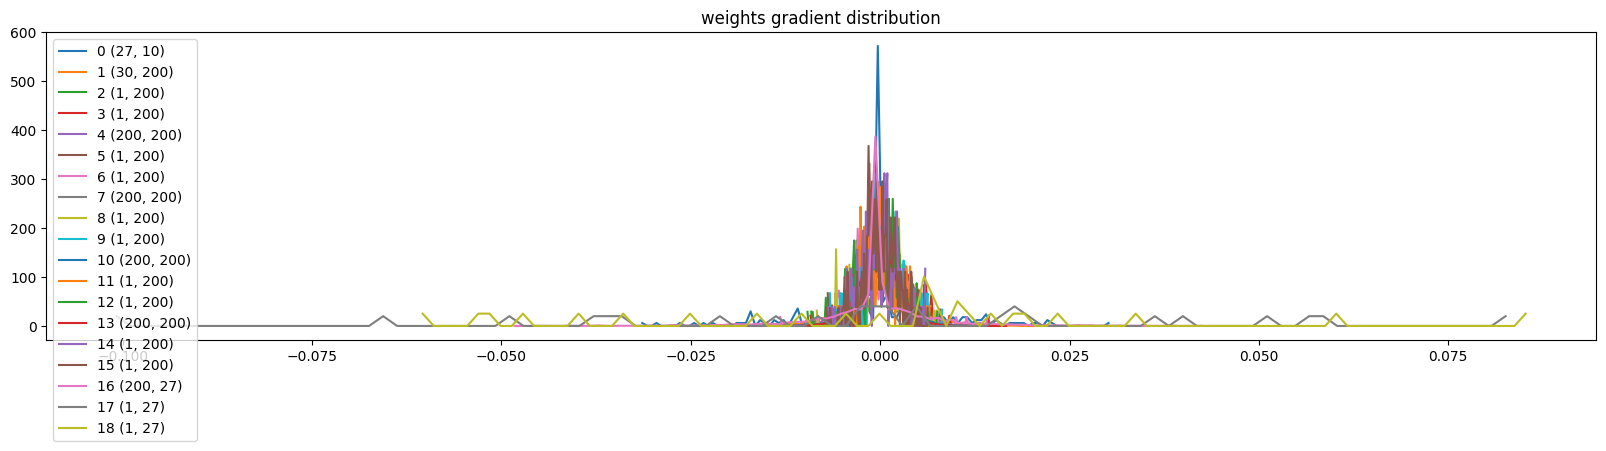

In [117]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2: ## checking only weights
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

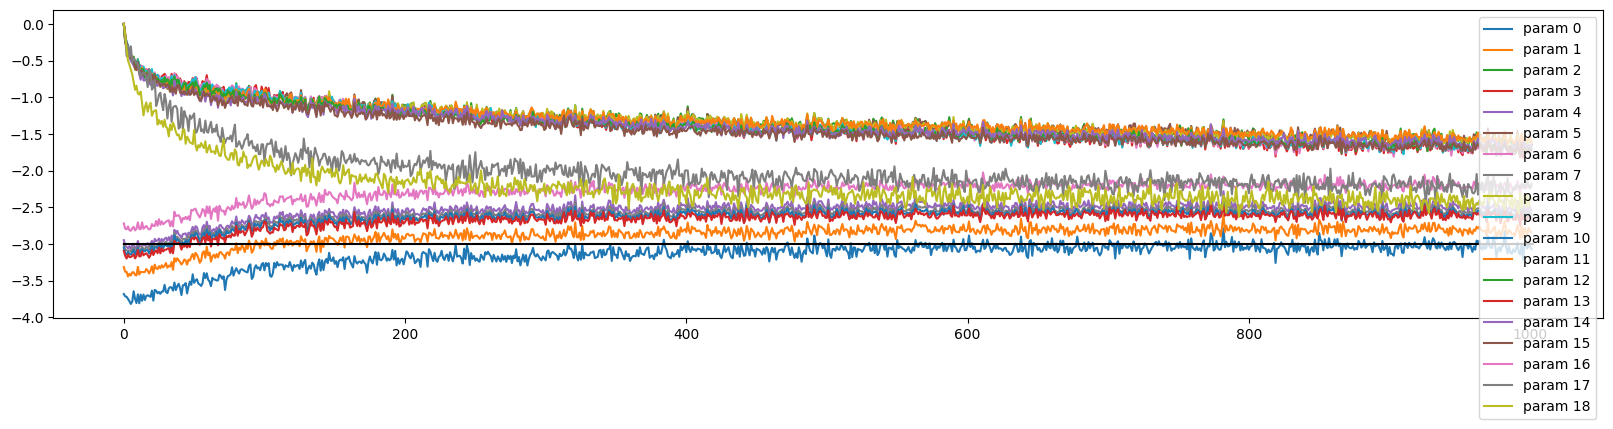

In [118]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([update_to_data[j][i] for j in range(len(update_to_data))])
    legends.append('param %d' % i)
plt.plot([0, len(update_to_data)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);